#imports

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#reading dataset

In [45]:
df = pd.read_csv('/content/logistic_regression_2d_dataset.csv')

In [46]:
df.head()

,X1,X2,Output
0,-0.322745,0.383932,0
1,-0.215825,1.213315,0
2,0.953985,-0.416727,0
3,-0.084019,0.580157,0
4,-0.098995,0.347869,0


#X and y

In [47]:
X = df.drop(['Output'],axis=1).to_numpy()
y = df['Output'].to_numpy()

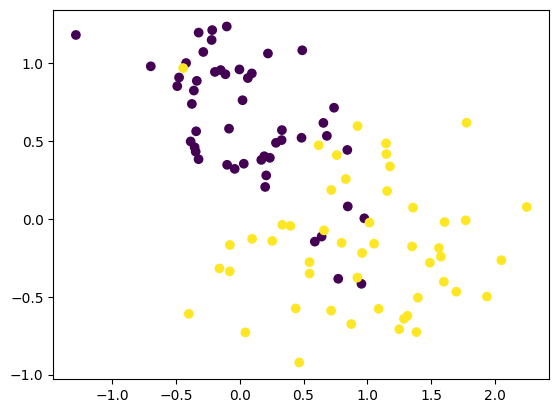

In [48]:
plt.scatter(X[:,0],X[:,1],c=y)

#training a logistic regression model

In [49]:
from sklearn.linear_model import LogisticRegression
clf = LogisticRegression()

In [50]:
clf.fit(X,y)

LogisticRegression()

#ploting decision regions using mlxtend

<Axes: >

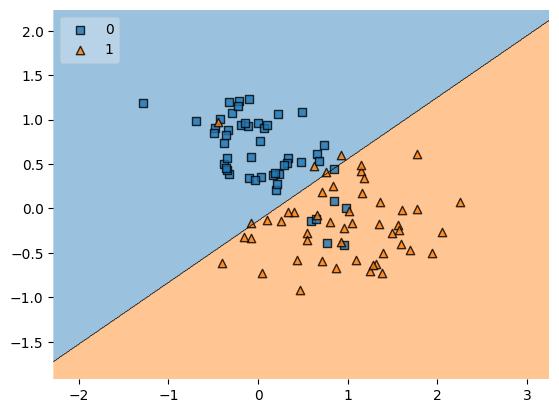

In [51]:
from mlxtend.plotting import plot_decision_regions

plot_decision_regions(X, y.astype('int'), clf, legend=2)

#cross val

In [52]:
from sklearn.model_selection import cross_val_score
np.mean(cross_val_score(clf,X,y,scoring='accuracy',cv=10))

np.float64(0.89)

#applying polynimial feature

In [53]:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=3,include_bias=False)
X_trf = poly.fit_transform(X)

In [54]:
clf1 = LogisticRegression()
np.mean(cross_val_score(clf1,X_trf,y,scoring='accuracy',cv=10))

np.float64(0.8400000000000001)

In [55]:
def plot_decision_boundary(X,y,degree=1):

    poly = PolynomialFeatures(degree=degree)
    X_trf = poly.fit_transform(X)

    clf = LogisticRegression()
    clf.fit(X_trf,y)

    accuracy = np.mean(cross_val_score(clf,X_trf,y,scoring='accuracy',cv=10))

    a=np.arange(start=X[:,0].min()-1, stop=X[:,0].max()+1, step=0.01)
    b=np.arange(start=X[:,1].min()-1, stop=X[:,1].max()+1, step=0.01)


    XX,YY=np.meshgrid(a,b)

    input_array=np.array([XX.ravel(),YY.ravel()]).T

    labels=clf.predict(poly.transform(input_array))

    plt.contourf(XX,YY,labels.reshape(XX.shape),alpha=0.5)
    plt.scatter(X[:,0],X[:,1], c=y)
    plt.title('Degree = {}, accuracy is {}'.format(degree,np.round(accuracy,4)))

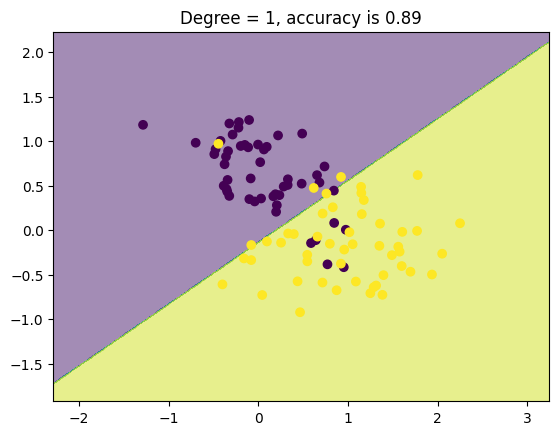

In [56]:
plot_decision_boundary(X,y)

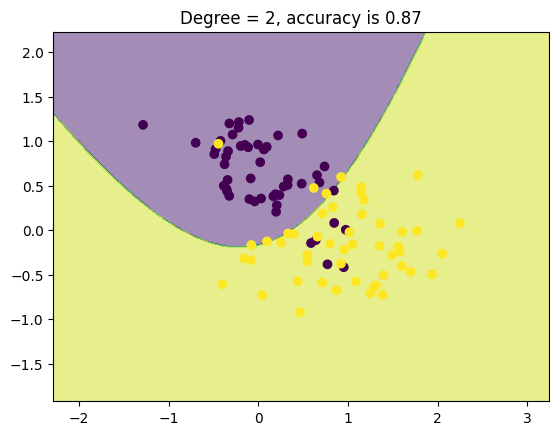

In [57]:
plot_decision_boundary(X,y,degree=2)

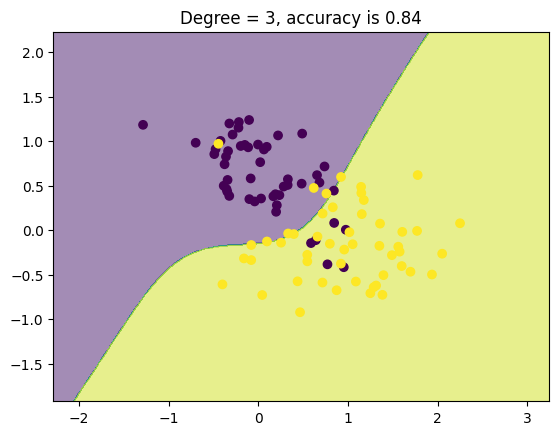

In [58]:
plot_decision_boundary(X,y,degree=3)

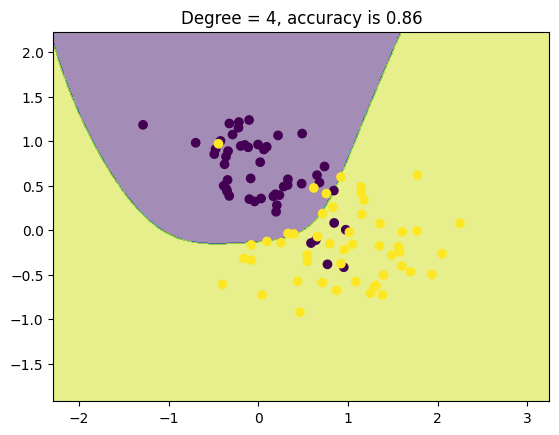

In [59]:
plot_decision_boundary(X,y,degree=4)

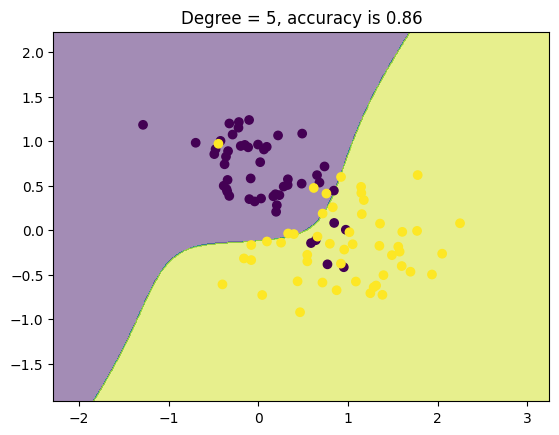

In [60]:
plot_decision_boundary(X,y,degree=5)

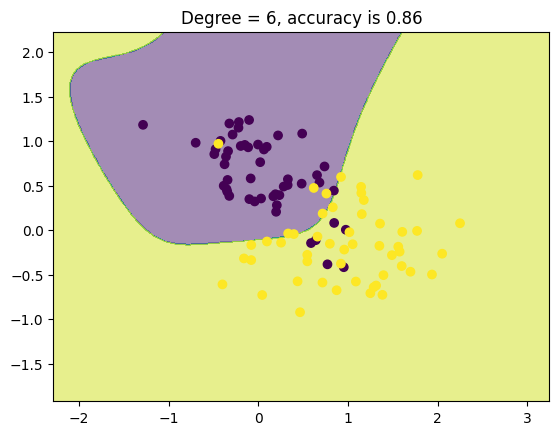

In [61]:
plot_decision_boundary(X,y,degree=6)

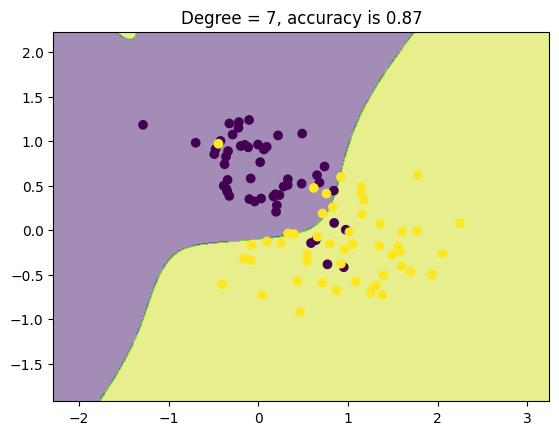

In [62]:
plot_decision_boundary(X,y,degree=7)

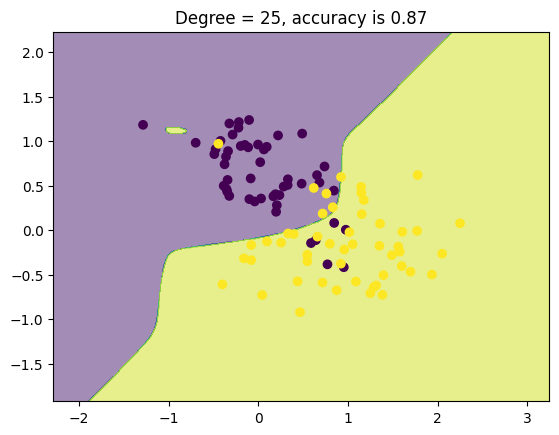

In [63]:
plot_decision_boundary(X,y,degree=25)